<a href="https://colab.research.google.com/github/Kizsi2025/05-kepek-13c-37/blob/main/kepek.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bolyai Labs – Feladatkártya #5: A gép lát

> Minőségellenőrként szeretném, ha a futószalag kamerája magától felismerné az alkatrészeket (kör, négyzet, háromszög, kereszt), és egy kész modell a raktári fotókon az embereket és a járműveket is megtalálná.

Öt lépésben haladsz:
- **a)** konvolúció kézzel: mit lát egy 3 × 3-as szűrő?
- **b)** alapvonal: a 4. blokk hálója (MLP) a képpontokon;
- **c)** konvolúciós háló (CNN) felépítése;
- **d)** a CNN tanítása és a **képosztályozási teszt** (legalább 93% a teszthalmazon);
- **e)** objektumdetektálás egy előtanított YOLOv8 modellel.

Ahol `...  # TODO` áll, oda írd a megoldást. **Mentés:** File → Save a copy in GitHub → saját repó, `main`, fájlnév `kepek.ipynb`, commitüzenet: `feat: képfelismerés CNN-nel és YOLO-val (feladatkártya #5)`.

Tanító: (3000, 1, 28, 28) | teszt: (600, 1, 28, 28) | osztályok: [np.str_('kör'), np.str_('négyzet'), np.str_('háromszög'), np.str_('kereszt')]


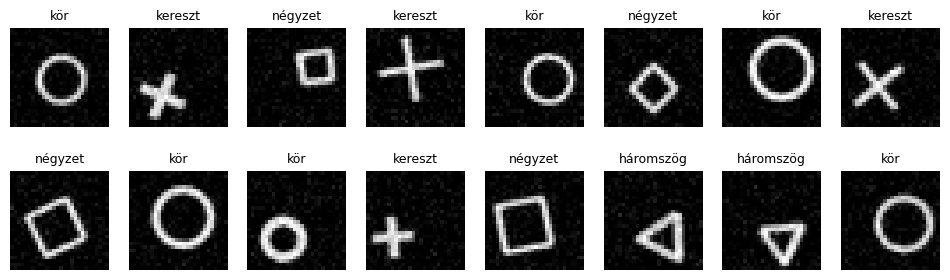

In [1]:
import io, json, urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn

ADAT = Path("data/alkatreszek.npz")
d = np.load(ADAT if ADAT.exists() else io.BytesIO(urllib.request.urlopen("https://raw.githubusercontent.com/Kizsi2025/bolyai-labs-05-kepek/main/data/alkatreszek.npz").read()))
OSZTALYOK = list(d["osztalyok"])
# Tenzorok: (képek száma, 1 csatorna, 28, 28), értékek 0 és 1 között
Xt = torch.tensor(d["X_train"], dtype=torch.float32).unsqueeze(1) / 255
yt = torch.tensor(d["y_train"])
Xv = torch.tensor(d["X_test"], dtype=torch.float32).unsqueeze(1) / 255
yv = torch.tensor(d["y_test"])
print("Tanító:", tuple(Xt.shape), "| teszt:", tuple(Xv.shape), "| osztályok:", OSZTALYOK)

fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for i, a in enumerate(ax.flat):
    a.imshow(Xt[i, 0], cmap="gray"); a.set_title(OSZTALYOK[yt[i]], fontsize=9); a.axis("off")
plt.show()

## a) Konvolúció kézzel
A szűrő (kernel) egy kis 3 × 3-as súlymátrix, amely végigcsúszik a képen: minden helyen összeszorozza a képpontokat a súlyokkal, és összeadja őket.
Az alábbi kép bal oldala sötét (0), jobb oldala világos (1). A szűrő a **függőleges éleket** keresi. Számold ki fejben az első sort, aztán futtasd le a gépen is!

In [2]:
kep = torch.tensor([[0., 0., 1., 1., 1.]] * 5).reshape(1, 1, 5, 5)
szuro = torch.tensor([[-1., 0., 1.]] * 3).reshape(1, 1, 3, 3)
terkep = F.conv2d(kep, szuro)
print(terkep[0, 0])
konv = terkep[0, 0].tolist()

tensor([[3., 3., 0.],
        [3., 3., 0.],
        [3., 3., 0.]])


In [3]:
def tanit(modell, epochok=8, lr=0.003, batch=64):
    """Mini-batch tanítás: egy lépésben csak 64 képből számolunk."""
    opt = torch.optim.Adam(modell.parameters(), lr=lr)
    lossfv = nn.CrossEntropyLoss()  # több osztálynál ez a veszteség
    g = torch.Generator().manual_seed(0)
    for epoch in range(epochok):
        for idx in torch.randperm(len(Xt), generator=g).split(batch):
            opt.zero_grad()
            veszteseg = lossfv(modell(Xt[idx]), yt[idx])
            veszteseg.backward()
            opt.step()
        print(f"{epoch + 1}. epoch, veszteség: {veszteseg.item():.3f}")

def pontossag(modell, X, y):
    with torch.no_grad():
        return (modell(X).argmax(1) == y).float().mean().item()

def parameterek(modell):
    return sum(p.numel() for p in modell.parameters())

## b) Alapvonal: a 4. blokk hálója
Az MLP minden képpontot külön bemenetnek lát (784 szám), és nem tudja, melyik képpont melyiknek a szomszédja. A tanítási ciklus a 4. blokkból ismerős – csak most kötegekben (mini-batch) tanítunk.

In [4]:
torch.manual_seed(0)
mlp = nn.Sequential(nn.Flatten(), nn.Linear(784, 64), nn.ReLU(), nn.Linear(64, 4))
tanit(mlp)
mlp_pont = pontossag(mlp, Xv, yv)
print("MLP – paraméterek:", parameterek(mlp), "| pontosság:", round(mlp_pont, 3))

1. epoch, veszteség: 1.188
2. epoch, veszteség: 0.772
3. epoch, veszteség: 0.737
4. epoch, veszteség: 0.580
5. epoch, veszteség: 0.676
6. epoch, veszteség: 0.454
7. epoch, veszteség: 0.452
8. epoch, veszteség: 0.460
MLP – paraméterek: 50500 | pontosság: 0.747


## c) Konvolúciós háló (CNN)
Építsd fel a hálót rétegenként:

| Réteg | Mit csinál | Kimenet mérete |
| --- | --- | --- |
| `nn.Conv2d(1, 16, 3, padding=1)`, `nn.ReLU()` | 16 szűrő keres mintázatokat | 16 × 28 × 28 |
| `nn.MaxPool2d(2)` | felezi a képet: 2 × 2-ből a legnagyobb marad | 16 × 14 × 14 |
| `nn.Conv2d(16, 32, 3, padding=1)`, `nn.ReLU()` | 32 szűrő a mintázatok mintázataira | 32 × 14 × 14 |
| `nn.MaxPool2d(2)` | újra felez | 32 × 7 × 7 |
| `nn.Flatten()`, `nn.Linear(32 * 7 * 7, 32)`, `nn.ReLU()` | kiterítés, döntő réteg | 32 |
| `nn.Linear(32, 4)` | egy kimenet osztályonként | 4 |

In [5]:
torch.manual_seed(0)
cnn = nn.Sequential(
    nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(),nn.MaxPool2d(2),nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),nn.MaxPool2d(2),nn.Flatten(), nn.Linear(32 * 7 * 7, 32), nn.ReLU(),nn.Linear(32, 4)
)
print(cnn(Xt[:1]).shape)  # torch.Size([1, 4]) kell
print("CNN – paraméterek:", parameterek(cnn))

torch.Size([1, 4])
CNN – paraméterek: 55140


## d) Tanítás és képosztályozási teszt
Tanítsd a CNN-t ugyanazzal a `tanit` függvénnyel, és mérd meg a pontosságát a 600 képes teszthalmazon. **A teszt: legalább 93%.**

In [7]:
tanit(cnn)
cnn_pont = pontossag(cnn, Xv, yv)
print("CNN pontossága:", round(cnn_pont, 3), "| MLP:", round(mlp_pont, 3))

1. epoch, veszteség: 0.023
2. epoch, veszteség: 0.021
3. epoch, veszteség: 0.012
4. epoch, veszteség: 0.008
5. epoch, veszteség: 0.009
6. epoch, veszteség: 0.007
7. epoch, veszteség: 0.025
8. epoch, veszteség: 0.002
CNN pontossága: 0.99 | MLP: 0.747


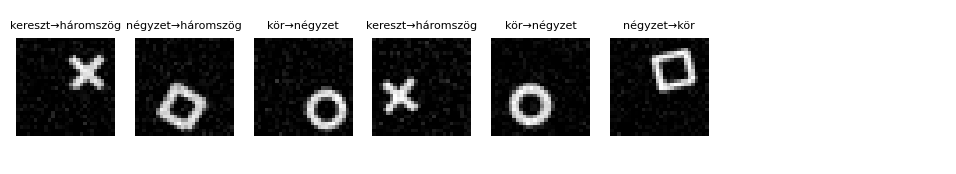

In [8]:
# Hol téved még? Az első 8 hibás teszt kép
with torch.no_grad():
    jo = cnn(Xv).argmax(1)
hibas = (jo != yv).nonzero().flatten()[:8]
fig, ax = plt.subplots(1, 8, figsize=(12, 2))
for a in ax: a.axis("off")
for a, i in zip(ax, hibas):
    a.imshow(Xv[i, 0], cmap="gray"); a.set_title(f"{OSZTALYOK[yv[i]]}→{OSZTALYOK[jo[i]]}", fontsize=8)
plt.show()

## e) Objektumdetektálás YOLOv8-cal
A YOLO („You Only Look Once”) nemcsak megmondja, mi van a képen, hanem **bekeretezi** is: minden találathoz ad egy osztályt, egy bizalmi értéket és egy keretet.
Nem mi tanítjuk: egy 80 osztályon (ember, busz, autó …) **előtanított** modellt futtatunk. Az első futás letölti a kb. 6 MB-os `yolov8n.pt` fájlt.

In [9]:
%pip install -q ultralytics

bus      0.87  keret: [23, 231, 805, 757]
person   0.87  keret: [49, 399, 245, 903]
person   0.85  keret: [669, 392, 810, 877]
person   0.83  keret: [222, 406, 345, 858]
Emberek a képen: 3


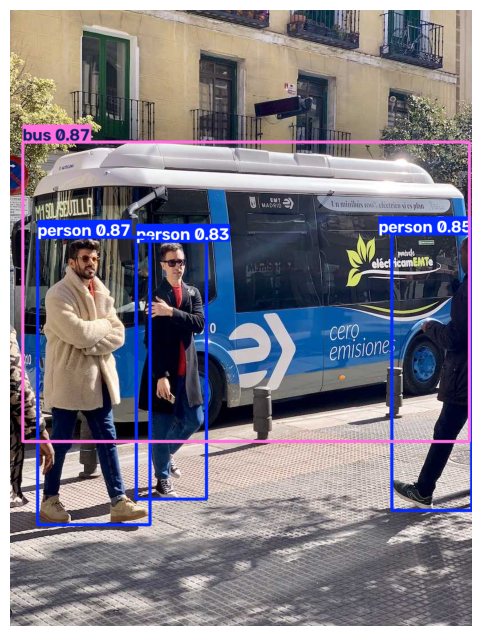

In [14]:
from ultralytics import YOLO
from ultralytics.utils import ASSETS

yolo = YOLO("yolov8n.pt")
talalat = yolo(ASSETS / "bus.jpg", conf=0.5, verbose=False)[0]
nevek = [talalat.names[int(c)] for c in talalat.boxes.cls]
for nev, bizalom, keret in zip(nevek, talalat.boxes.conf.tolist(), talalat.boxes.xyxy.round().int().tolist()):
    print(f"{nev:8s} {bizalom:.2f}  keret: {keret}")
emberek = nevek.count('person')
print("Emberek a képen:", emberek)
plt.figure(figsize=(6, 8)); plt.imshow(talalat.plot()[:, :, ::-1]); plt.axis("off"); plt.show()

## Önellenőrzés és mentés

In [15]:
assert konv == [[3.0, 3.0, 0.0]] * 3, "a) Nézd át: F.conv2d(kep, szuro)."
assert parameterek(cnn) == 55140, "c) A CNN rétegei nem egyeznek a táblázattal."
assert cnn_pont >= 0.93, "d) A CNN nem érte el a 93%-ot."
assert emberek == nevek.count('person'), "e) Számold meg a 'person' találatokat."
Path("eredmenyek").mkdir(exist_ok=True)
json.dump({"konv": konv, "mlp_pont": mlp_pont, "mlp_param": parameterek(mlp), "cnn_param": parameterek(cnn),
           "cnn_pont": cnn_pont, "yolo_nevek": nevek, "emberek": emberek},
          open("eredmenyek/kartya5.json", "w"), indent=1)
print("Minden ellenőrzés rendben!", {"MLP": round(mlp_pont, 3), "CNN": round(cnn_pont, 3), "emberek": emberek})

Minden ellenőrzés rendben! {'MLP': 0.747, 'CNN': 0.99, 'emberek': 3}


## Extra (nem kötelező)
Futtasd újra a YOLO-t `conf=0.25`-tel egy új cellában. Mi jelenik meg pluszban, és miért? Helyes találatok ezek?

**Gondolkodj el (a kilépőkérdésekhez):** a CNN és az MLP paramétereinek száma hasonló. Miért tanul mégis sokkal jobban a CNN a képekből?